# §5 Labels and Bias Audit (Stage S5)

A diabetes label is itself a measurement. Self-report records a past diagnosis and HbA1c records today's
glycaemia under whatever treatment the person receives; neither is "the truth". This section audits the label
layer and two further bias layers before the target is frozen (freeze point 2, `target-freeze`):

| Step | Question | Output |
|---|---|---|
| 1 | How far do self-report and HbA1c agree? | confusion table, κ, PA/NA (`label_audit.csv`) |
| 2 | Does treatment hide diabetes from HbA1c? | treatment masking, A1c-by-medication figure |
| 3 | What does "undiagnosed" mean? | care contact of the undiagnosed |
| 4 | Who is undiagnosed? | risk differences, Korn–Graubard CIs, NCHS flags (`undiagnosed_by_group.csv`) |
| 5 | Does BMI measure adiposity equally for Asian adults? | BMI vs WHtR AUC by race (`bmi_race_roc.csv`) |
| 6 | Whom do the 5,730 represent? | sample vs weighted shares, response, exam selection (`representation.csv`) |
| 7 | Is HbA1c missing at random? | missingness by race, Manski bounds |
| 8 | Decision gate L2 and freeze | C1–C4, `L_comb`, E-SCREEN, 3×3 strata, SL1–SL7 (`governance/label_freeze.md`) |

All findings here were obtained after looking at the data (`prior_exposure = analysis_seen`); they motivate,
but do not count as, pre-registered tests.

In [1]:
import sys, pathlib
_here = pathlib.Path.cwd()
ROOT = next(p for p in [_here, *_here.parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))
from src import config as C, plots, results_io as R

import hashlib
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.metrics import roc_auc_score

from src import evalkit as E, labels as L, nhanes_io as NIO, survey as S

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
OUT = C.RESULTS_DIR / "S5"
OUT.mkdir(parents=True, exist_ok=True)
WT = C.WEIGHT_PHLEB                      # WTPH2YR: cohort analyses (HbA1c sample)
REG_DATE = "2026-10-11"
RACE = {1: "Mexican American", 2: "Other Hispanic", 3: "NH White", 4: "NH Black", 6: "NH Asian", 7: "Other/multi"}
RES: dict = {}                           # -> results/metrics_S5.json
REG: list[dict] = []                     # -> governance/register/S5.csv


def close(value, target, tol, what):
    """Assert a recomputed number against the verified value of process doc §8 / S5 plan."""
    assert abs(value - target) <= tol, f"{what}: got {value:.4f}, expected {target} ± {tol}"


def register(dr_id, type_, finding, evidence_ref, evidence_value, decision, alternatives_rejected,
             *, hyp_id="", status="decided", check_verdict="PASS", check_note="", loop_ref=""):
    REG.append(dict(dr_id=dr_id, stage="S5", date=REG_DATE, type=type_, finding=finding,
                    evidence_ref=evidence_ref, evidence_value=evidence_value, decision=decision,
                    alternatives_rejected=alternatives_rejected, hyp_id=hyp_id, status=status,
                    check_verdict=check_verdict, check_note=check_note, loop_ref=loop_ref,
                    change_request="", commit=""))


def pct(x, nd=1):
    return f"{100 * x:.{nd}f}%"


def kg_text(r):
    flag = "exploratory, does not meet NCHS standard" if r["nchs_flags"] else "meets NCHS standard"
    return (f"{pct(r['est'])} (KG {pct(r['kg_low'])}–{pct(r['kg_high'])}, width {r['ci_width']:.2f}; "
            f"n={r['n']}, events={r['n_events']}, df={r['df']}) -> {flag}")


cohort = NIO.build_cohort()
cohort.attrs = {}   # drop the attached sentinel-audit DataFrame (pandas cannot compare DataFrame attrs in concat)
d = L.add_labels(cohort)
assert len(d) == NIO.COHORT_N == 5730
d["race3"] = d["RIDRETH3"].map(RACE)
print(f"cohort: {len(d):,} adults; columns: {d.shape[1]}")

cohort: 5,730 adults; columns: 81


## 1 Three labels and their agreement

**Why.** The research question needs a diabetes label, and the data offer two independent instruments:
`L_self` (DIQ010 = 1, "a doctor told you that you have diabetes") and `L_A1c` (HbA1c ≥ 6.5 %, measured at the
exam). `L_comb` is their union. Before choosing one, we measure how much they agree. Cohen's κ is reported
unweighted and weighted (WTPH2YR, delete-one-PSU jackknife, df = 15). Because κ depends on prevalence, the
positive and negative specific agreements (PA, NA) are reported alongside, as well as the sensitivity and PPV
of self-report against HbA1c.

In [2]:
tab = L.confusion(d)
print("Self-report (rows) x HbA1c >= 6.5 (columns), unweighted counts")
print(tab, "\n")
unw = L.agreement(d)
jk_agree = S.jackknife(d, L.agreement_vector, weight=WT)
agree = pd.DataFrame({
    "unweighted": [unw[k] for k in L.AGREEMENT_KEYS],
    "weighted": jk_agree["est"], "w_ci_low": jk_agree["ci_low"], "w_ci_high": jk_agree["ci_high"],
}, index=list(L.AGREEMENT_KEYS)).round(3)
print(agree)

L.check_frozen_counts(d)
close(unw["kappa"], 0.699, 0.0015, "kappa unweighted")
close(unw["pa"], 0.739, 0.0015, "PA")
close(unw["na"], 0.959, 0.0015, "NA")
close(unw["sens"], 0.789, 0.0015, "sensitivity of self-report")
close(unw["ppv"], 0.695, 0.0015, "PPV of self-report")
close(jk_agree["est"][0], 0.709, 0.0015, "kappa weighted")
close(jk_agree["ci_low"][0], 0.665, 0.002, "kappa weighted CI low")
close(jk_agree["ci_high"][0], 0.752, 0.002, "kappa weighted CI high")

n_comb = int(d["L_comb"].sum())
miss_self, miss_a1c = int(tab.loc[0, 1]), int(tab.loc[1, 0])
w_prev = S.weighted_prop(d, "L_comb", weight=WT)
print(f"\nL_comb positives {n_comb} ({pct(n_comb / len(d))} unweighted; weighted {kg_text(w_prev)})")
print(f"L_self misses {miss_self}/{n_comb} = {pct(miss_self / n_comb)} of L_comb positives; "
      f"L_A1c misses {miss_a1c}/{n_comb} = {pct(miss_a1c / n_comb)}")
close(w_prev["est"], 0.140, 0.0015, "weighted L_comb prevalence")

label_audit = pd.DataFrame([
    {"label": lab, "positives": int(d[lab].sum()), "prev_unweighted": d[lab].mean(),
     **{f"w_{k}": v for k, v in S.weighted_prop(d, lab, weight=WT).items()
        if k in ("est", "kg_low", "kg_high", "df")}}
    for lab in L.LABEL_COLS])
label_audit.to_csv(OUT / "label_audit.csv", index=False)
agree.to_csv(OUT / "label_agreement.csv")
RES["labels"] = {
    "confusion": {f"self{i}_a1c{j}": int(tab.loc[i, j]) for i in (0, 1) for j in (0, 1)},
    "agreement_unweighted": {k: unw[k] for k in L.AGREEMENT_KEYS},
    "agreement_weighted": {k: {"est": e, "ci_low": lo, "ci_high": hi} for k, e, lo, hi in
                           zip(L.AGREEMENT_KEYS, jk_agree["est"], jk_agree["ci_low"], jk_agree["ci_high"])},
    "positives": {lab: int(d[lab].sum()) for lab in L.LABEL_COLS},
    "L_comb_weighted": {k: w_prev[k] for k in ("est", "ci_low", "ci_high", "kg_low", "kg_high")},
    "L_comb_unweighted": n_comb / len(d),
    "self_missed_share": miss_self / n_comb, "a1c_missed_share": miss_a1c / n_comb,
}
register("DR-S5-02", "label_audit",
         "Self-report and HbA1c are two different instruments with moderate-to-substantial agreement",
         "results/S5/label_agreement.csv; §5.1",
         f"kappa {unw['kappa']:.3f} (weighted {jk_agree['est'][0]:.3f}, CI {jk_agree['ci_low'][0]:.3f}-"
         f"{jk_agree['ci_high'][0]:.3f}); PA {unw['pa']:.3f}; NA {unw['na']:.3f}; sens {unw['sens']:.3f}; PPV {unw['ppv']:.3f}",
         "Use the union L_comb as training target; report PA/NA next to kappa; keep L_self and L_A1c as sensitivity labels SL2/SL1",
         "Single-instrument label (L_self or L_A1c) as target; kappa alone (prevalence-dependent)",
         check_note="Confusion table, kappa, PA/NA, sens/PPV recomputed and asserted against process doc §8")

Self-report (rows) x HbA1c >= 6.5 (columns), unweighted counts
L_A1c      0    1
L_self           
0       4759  152
1        250  569 

       unweighted  weighted  w_ci_low  w_ci_high
kappa       0.699     0.709     0.665      0.752
pa          0.739     0.741     0.701      0.781
na          0.959     0.968     0.962      0.973
sens        0.789     0.784     0.738      0.830
ppv         0.695     0.703     0.652      0.753

L_comb positives 971 (16.9% unweighted; weighted 14.0% (KG 12.5%–15.7%, width 0.03; n=5730, events=971, df=15) -> meets NCHS standard)
L_self misses 152/971 = 15.7% of L_comb positives; L_A1c misses 250/971 = 25.7%


**So what.** The two instruments agree on 93 % of adults, but agreement *on cases* is much weaker: κ = 0.699
(weighted 0.709, CI 0.665–0.752, "substantial" on the Landis–Koch scale only just), PA = 0.739 against
NA = 0.959. Self-report detects 78.9 % of HbA1c-positive adults, and only 69.5 % of self-reported diabetics
are HbA1c-positive on the day of the exam. Each single instrument misses a large part of the union:
`L_self` misses 152/971 = 15.7 % of `L_comb` positives and `L_A1c` misses 250/971 = 25.7 %. The disagreement
is structured, not random noise; steps 2–3 show why.

## 2 Treatment masking

**Why.** 250 self-reported diabetics have HbA1c < 6.5 %. If most of them are treated, a low HbA1c is the
*result* of diagnosis and treatment, and an HbA1c-only label would call well-controlled patients "healthy".
Medication (insulin DIQ050, pills DIQ070) is post-diagnosis information, so it is used here for the audit only,
never as a feature.

self-reported diabetics: 819; HbA1c < 6.5: 250 (30.5%)
  of these on insulin or pills: 165 (66%); untreated: 85, of whom 50 have HbA1c 5.7-6.4
treated self-reported diabetics: 694; HbA1c < 6.5 among them: 23.8%

HbA1c (%) of self-reported diabetics by treatment
                  count  mean   std  min  25%  50%  75%   max
on_med                                                       
insulin or pills  694.0  7.64  1.75  4.1  6.5  7.2  8.3  17.1
no medication     125.0  6.53  1.72  4.7  5.6  6.1  6.7  15.6


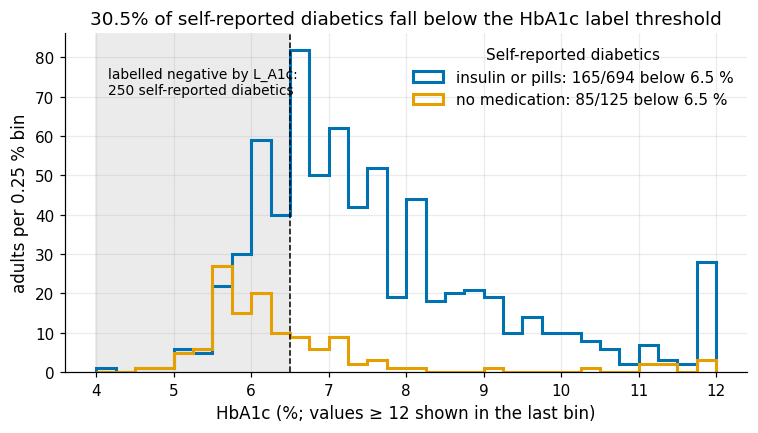

In [3]:
sr = d[d["L_self"] == 1]
ctrl = sr[sr["L_A1c"] == 0]
n_ctrl, n_ctrl_med = len(ctrl), int(ctrl["on_med"].sum())
unmed = ctrl[ctrl["on_med"] == 0]
n_unmed_pre = int(unmed["LBXGH"].between(5.7, 6.49).sum())
on_med = sr[sr["on_med"] == 1]
share_med_below = float((on_med["L_A1c"] == 0).mean())
print(f"self-reported diabetics: {len(sr)}; HbA1c < 6.5: {n_ctrl} ({pct(n_ctrl / len(sr))})")
print(f"  of these on insulin or pills: {n_ctrl_med} ({pct(n_ctrl_med / n_ctrl, 0)}); untreated: {len(unmed)}, "
      f"of whom {n_unmed_pre} have HbA1c 5.7-6.4")
print(f"treated self-reported diabetics: {len(on_med)}; HbA1c < 6.5 among them: {pct(share_med_below)}")
print("\nHbA1c (%) of self-reported diabetics by treatment")
print(sr.groupby(sr["on_med"].map({1: "insulin or pills", 0: "no medication"}))["LBXGH"]
      .describe(percentiles=[.25, .5, .75]).round(2))
assert (n_ctrl, n_ctrl_med, len(unmed), n_unmed_pre, len(on_med)) == (250, 165, 85, 50, 694)
close(n_ctrl / len(sr), 0.305, 0.001, "masking share")
close(share_med_below, 0.238, 0.001, "treated with HbA1c < 6.5")

fig, ax = plt.subplots(figsize=(8, 4))
bins = np.arange(4.0, 12.01, 0.25)
ax.axvspan(4.0, C.HBA1C_DIABETES, color="0.92", zorder=0)
for flag, lab, col in [(1, "insulin or pills", plots.PALETTE[4]), (0, "no medication", plots.PALETTE[0])]:
    x = sr.loc[sr["on_med"] == flag, "LBXGH"].clip(upper=11.99)
    below = int((x < C.HBA1C_DIABETES).sum())
    ax.hist(x, bins=bins, histtype="step", lw=2, color=col, label=f"{lab}: {below}/{len(x)} below 6.5 %")
ax.axvline(C.HBA1C_DIABETES, color="k", ls="--", lw=1)
ax.text(4.15, ax.get_ylim()[1] * 0.9, f"labelled negative by L_A1c:\n{n_ctrl} self-reported diabetics", fontsize=9, va="top")
ax.set(xlabel="HbA1c (%; values ≥ 12 shown in the last bin)", ylabel="adults per 0.25 % bin",
       title=f"{pct(n_ctrl / len(sr))} of self-reported diabetics fall below the HbA1c label threshold")
ax.legend(loc="upper right", title="Self-reported diabetics")
plots.savefig(fig, "S5_a1c_by_medication",
              caption=f"HbA1c distribution of the {len(sr)} self-reported diabetics by current insulin/pill use. "
                      f"{n_ctrl} ({pct(n_ctrl / len(sr))}) are below 6.5 %, {n_ctrl_med} of them treated.")
plt.show()

RES["masking"] = {"self_reported": len(sr), "below_6_5": n_ctrl, "below_6_5_share": n_ctrl / len(sr),
                  "below_6_5_on_med": n_ctrl_med, "below_6_5_untreated": len(unmed),
                  "untreated_5_7_to_6_4": n_unmed_pre, "treated": len(on_med),
                  "treated_below_6_5_share": share_med_below}
register("DR-S5-03", "label_bias",
         "Treatment masks diabetes in HbA1c: an HbA1c-only label turns controlled patients into negatives",
         "figures/S5_a1c_by_medication.png; §5.2",
         f"{n_ctrl}/{len(sr)} ({pct(n_ctrl / len(sr))}) self-reported diabetics have HbA1c<6.5; {n_ctrl_med} of them on medication; "
         f"{pct(share_med_below)} of treated patients below 6.5",
         "Reject L_A1c as the sole target; keep stratum D_controlled as a 3x3 evaluation column; medication is audit-only (post-diagnosis)",
         "HbA1c-only target; medication as a feature (leakage by the availability rule)")

**So what.** 250 of 819 self-reported diabetics (30.5 %) are below the HbA1c threshold, and 165 of these
(66 %) take insulin or pills; among all 694 treated patients 23.8 % are "controlled". The remaining 85 are
untreated, 50 of them in the prediabetes range (5.7–6.4 %), consistent with lifestyle-controlled or
early disease. An HbA1c-only label would therefore count successful treatment as absence of disease: this is
the *D_controlled* column of the 3×3 label matrix in S8.

## 3 What "undiagnosed" means

**Why.** The 152 adults with HbA1c ≥ 6.5 % who do not report diabetes are the population the screening use case
is about (E-SCREEN). "Undiagnosed" is easily read as "never saw a doctor". DIQ010 = 3 (borderline), DIQ180
(blood test for high blood sugar in the past three years) and DIQ160 (told prediabetes) show whether they
had contact with the system. Counts are unweighted; shares among the undiagnosed are also weighted with
Korn–Graubard intervals.

In [4]:
bl = d["DIQ010"].eq(3)
no = d["DIQ010"].eq(2)
p_bl, p_no = d.loc[bl, "L_A1c"].mean(), d.loc[no, "L_A1c"].mean()
print(f"DIQ010 = 3 (borderline): {int(bl.sum())}; HbA1c >= 6.5: {int(d.loc[bl, 'L_A1c'].sum())} ({pct(p_bl)}) "
      f"vs DIQ010 = 2: {pct(p_no)}")
und_mask = (d["stratum_3x3"] == "Undiagnosed").to_numpy()
und = d[und_mask]
care = {
    "told borderline (DIQ010=3)": und["DIQ010"].eq(3),
    "blood test past 3 years (DIQ180=1)": und["DIQ180"].eq(1),
    "told prediabetes (DIQ160=1)": und["DIQ160"].eq(1),
}
rows = []
for name, s in care.items():
    y = np.where(und_mask, d.index.isin(s[s].index), np.nan)
    w = S.weighted_prop(d, y.astype(float), weight=WT, domain=und_mask)
    rows.append({"contact": name, "n": int(s.sum()), "of": len(und), "share": s.sum() / len(und),
                 "w_est": w["est"], "kg_low": w["kg_low"], "kg_high": w["kg_high"], "df": w["df"],
                 "flags": ";".join(w["nchs_flags"])})
care_tab = pd.DataFrame(rows)
print(care_tab.round(3).to_string(index=False))
print(f"DIQ180 missing among undiagnosed: {int(und['DIQ180'].isna().sum())}; DIQ160 missing: {int(und['DIQ160'].isna().sum())} "
      "(borderline respondents skip DIQ160)")
assert int(bl.sum()) == 213 and int(d.loc[bl, "L_A1c"].sum()) == 36 and len(und) == 152
assert care_tab["n"].tolist() == [36, 104, 48]
close(p_bl, 0.169, 0.001, "borderline A1c+ share")
close(p_no, 0.025, 0.001, "DIQ010=2 A1c+ share")
care_tab.to_csv(OUT / "undiagnosed_care_contact.csv", index=False)
RES["undiagnosed_meaning"] = {"borderline_n": int(bl.sum()), "borderline_a1c_pos": int(d.loc[bl, "L_A1c"].sum()),
                              "borderline_a1c_share": p_bl, "no_a1c_share": p_no, "undiagnosed": len(und),
                              "contact": care_tab.set_index("contact")[["n", "share", "w_est", "kg_low", "kg_high"]].to_dict("index")}
register("DR-S5-04", "label_semantics",
         "Most undiagnosed adults had contact with the health system: the gap is diagnosis/communication, not only access",
         "results/S5/undiagnosed_care_contact.csv; §5.3",
         f"of 152 undiagnosed: 36 told borderline (24%), 104 blood-tested in past 3 y (68%), 48 told prediabetes",
         "Frame E-SCREEN positives as 'not diagnosed despite contact'; DIQ160/DIQ180 excluded as features (post-test information); borderline kept negative in L_comb and flagged",
         "Describe undiagnosed as 'no access to care'; use DIQ180 as a screening feature")

DIQ010 = 3 (borderline): 213; HbA1c >= 6.5: 36 (16.9%) vs DIQ010 = 2: 2.5%
                           contact   n  of  share  w_est  kg_low  kg_high  df flags
        told borderline (DIQ010=3)  36 152  0.237  0.235   0.165    0.317  15      
blood test past 3 years (DIQ180=1) 104 152  0.684  0.625   0.536    0.708  15      
       told prediabetes (DIQ160=1)  48 152  0.316  0.306   0.228    0.395  15      
DIQ180 missing among undiagnosed: 2; DIQ160 missing: 37 (borderline respondents skip DIQ160)


**So what.** Borderline respondents are almost seven times as likely to be HbA1c-positive as those answering
"no" (16.9 % vs 2.5 %). Of the 152 undiagnosed, 104 (68 %) had a blood-sugar test in the past three years,
36 (24 %) were told they were borderline and 48 were told they had prediabetes. "Undiagnosed" is therefore
mostly a diagnosis and communication gap, not a lack of any contact. This is also why DIQ160 and DIQ180 are
excluded as features: they record the result of a glucose test, which the screening use case comes before.

## 4 Who is undiagnosed

**Why.** If the undiagnosed share differs by insurance, access or race, then `L_self` is a biased label
and a model trained on it inherits the bias. The domain is all adults with HbA1c ≥ 6.5 % (n = 721) and the
outcome is "not self-reported". Following NCHS presentation standards, proportions get Korn–Graubard intervals
with the design-based effective sample size and domain df (strata containing the domain), and every estimate
whose CI width is ≥ 0.30 (or n/n_eff < 30, df < 8) is labelled *exploratory, does not meet NCHS standard*.
The headline quantity is the risk difference (WTPH2YR, delete-one-PSU jackknife, df = domain df) rather than a
small-cell proportion.

In [5]:
d["undx"] = 1.0 - d["L_self"]
d["uninsured"] = np.select([d["HIQ011"].eq(2), d["HIQ011"].eq(1)], [1.0, 0.0], np.nan)
d["no_usual_place"] = np.select([d["HUQ030"].eq(2), d["HUQ030"].isin([1, 3])], [1.0, 0.0], np.nan)
a1c_dom = d["L_A1c"].eq(1).to_numpy()


def risk_difference(df, y, ga, gb, weight=WT):
    """Weighted risk difference p(a) - p(b) with JK CI (df = strata containing a or b)."""
    yv = df[y].to_numpy(float)
    ok = ~np.isnan(yv)
    a, b = np.asarray(ga) & ok, np.asarray(gb) & ok
    y0 = np.nan_to_num(yv)

    def f(_d, w):
        return np.dot(w * a, y0) / np.sum(w * a) - np.dot(w * b, y0) / np.sum(w * b)
    return S.jackknife(df, f, weight=weight, df_override=S.domain_df(df, a | b))


contrasts = [  # (name, column, level a, level b, label a, label b)
    ("uninsured - insured", "uninsured", 1.0, 0.0, "uninsured", "insured"),
    ("no usual place - usual place", "no_usual_place", 1.0, 0.0, "no usual place", "usual place"),
    ("NH Asian - NH White", "RIDRETH3", 6, 3, "NH Asian", "NH White"),
]
prop_rows, rd_rows = [], []
for name, col, a, b, la, lb in contrasts:
    for lev, lab in [(a, la), (b, lb)]:
        r = S.weighted_prop(d, "undx", weight=WT, domain=a1c_dom & d[col].eq(lev).to_numpy())
        prop_rows.append({"group": lab, "contrast": name, **{k: r[k] for k in
                          ("n", "n_events", "est", "kg_low", "kg_high", "ci_width", "n_eff", "df")},
                          "nchs": "exploratory, does not meet NCHS standard" if r["nchs_flags"] else "meets NCHS standard",
                          "flags": ";".join(r["nchs_flags"])})
    rd = risk_difference(d, "undx", a1c_dom & d[col].eq(a).to_numpy(), a1c_dom & d[col].eq(b).to_numpy())
    rd_rows.append({"contrast": name, "rd_pp": 100 * rd["est"], "ci_low_pp": 100 * rd["ci_low"],
                    "ci_high_pp": 100 * rd["ci_high"], "df": rd["df"]})
props = pd.DataFrame(prop_rows).drop_duplicates("group")
rds = pd.DataFrame(rd_rows)
print("Undiagnosed share among HbA1c >= 6.5 (WTPH2YR, Korn-Graubard)")
print(props.drop(columns="flags").round(3).to_string(index=False))
print("\nRisk differences (percentage points, JK CI)")
print(rds.round(1).to_string(index=False))

P = props.set_index("group")
close(P.loc["uninsured", "est"], 0.430, 0.0015, "uninsured share"); assert P.loc["uninsured", "n"] == 49
close(P.loc["uninsured", "kg_low"], 0.248, 0.002, "uninsured KG low"); close(P.loc["uninsured", "kg_high"], 0.627, 0.002, "uninsured KG high")
close(P.loc["insured", "est"], 0.199, 0.0015, "insured share")
close(P.loc["no usual place", "est"], 0.403, 0.0015, "no usual place share"); assert P.loc["no usual place", "n"] == 41
close(P.loc["NH Asian", "est"], 0.362, 0.0015, "Asian share"); assert P.loc["NH Asian", "n"] == 40 and P.loc["NH Asian", "df"] == 8
close(P.loc["NH Asian", "kg_low"], 0.165, 0.002, "Asian KG low"); close(P.loc["NH Asian", "kg_high"], 0.601, 0.002, "Asian KG high")
for g in ("uninsured", "no usual place", "NH Asian"):
    assert P.loc[g, "ci_width"] >= C.NCHS_CI_WIDTH_MAX and P.loc[g, "nchs"].startswith("exploratory")
assert P.loc["insured", "nchs"] == "meets NCHS standard"
RD = rds.set_index("contrast")
for name, (e, lo, hi) in {"uninsured - insured": (23.2, 6.2, 40.1), "no usual place - usual place": (20.0, -1.6, 41.6),
                          "NH Asian - NH White": (15.6, -5.7, 36.9)}.items():
    close(RD.loc[name, "rd_pp"], e, 0.15, name); close(RD.loc[name, "ci_low_pp"], lo, 0.15, name + " low")
    close(RD.loc[name, "ci_high_pp"], hi, 0.15, name + " high")

Undiagnosed share among HbA1c >= 6.5 (WTPH2YR, Korn-Graubard)


         group                     contrast   n  n_events   est  kg_low  kg_high  ci_width   n_eff  df                                     nchs
     uninsured          uninsured - insured  49        18 0.430   0.248    0.627     0.379  33.776  12 exploratory, does not meet NCHS standard
       insured          uninsured - insured 670       133 0.199   0.157    0.246     0.088 392.084  15                      meets NCHS standard
no usual place no usual place - usual place  41        17 0.403   0.210    0.621     0.411  26.951  14 exploratory, does not meet NCHS standard
   usual place no usual place - usual place 680       135 0.203   0.158    0.256     0.098 327.872  15                      meets NCHS standard
      NH Asian          NH Asian - NH White  40        12 0.362   0.165    0.601     0.436  26.575   8 exploratory, does not meet NCHS standard
      NH White          NH Asian - NH White 362        74 0.206   0.141    0.284     0.143 157.677  15                      meets NCHS 

**Adjusted model.** Insurance, a usual place of care and race are correlated (and all correlate with age), so
each contrast is also estimated in a logistic model of "undiagnosed" among the HbA1c-positive adults,
adjusted for age, sex and BMI. The primary fit is unweighted (model-based CI), matching the S5 plan; a
WTPH2YR-weighted fit with jackknife CIs is shown as a design-based sensitivity check.

In [6]:
FORM = "undx ~ no_usual_place + uninsured + race_cat + age10 + male + BMXBMI"   # reference race: NH White
RACE_LEVELS = ["NH White", *[r for r in RACE.values() if r != "NH White"]]
lg = d[a1c_dom].assign(age10=lambda x: x["RIDAGEYR"] / 10, male=lambda x: x["RIAGENDR"].eq(1).astype(float),
                       race_cat=lambda x: pd.Categorical(x["race3"], categories=RACE_LEVELS))
lg = lg.dropna(subset=["undx", "no_usual_place", "uninsured", "race3", "age10", "BMXBMI"])
fit = smf.logit(FORM, data=lg).fit(disp=0)
KEYS = {"no_usual_place": "no usual place", "uninsured": "uninsured", "race_cat[T.NH Asian]": "NH Asian"}
ci = fit.conf_int()
logit_tab = pd.DataFrame({"term": list(KEYS.values()), "OR": np.exp(fit.params[list(KEYS)]).values,
                          "ci_low": np.exp(ci.loc[list(KEYS), 0]).values, "ci_high": np.exp(ci.loc[list(KEYS), 1]).values})


def wlogit_logor(df, w):
    m = w > 0
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        f = smf.glm(FORM, data=df[m], family=sm.families.Binomial(), freq_weights=w[m] / w[m].mean()).fit()
    return f.params[list(KEYS)].to_numpy()


jk_lg = S.jackknife(lg, wlogit_logor, weight=WT)
logit_tab["OR_w"] = np.exp(jk_lg["est"])
logit_tab["w_ci_low"] = np.exp(jk_lg["ci_low"])
logit_tab["w_ci_high"] = np.exp(jk_lg["ci_high"])
n_dom = int(a1c_dom.sum())
print(f"complete cases n = {len(lg)} of {n_dom} (dropped: {int(d.loc[a1c_dom, 'BMXBMI'].isna().sum())} without BMI, "
      f"{int(d.loc[a1c_dom, 'uninsured'].isna().sum())} with unknown insurance); undiagnosed events = {int(lg['undx'].sum())}")
print(logit_tab.round(2).to_string(index=False))
LT = logit_tab.set_index("term")
# S5 plan: n=706, OR 2.84 / 1.80 / 1.69. Our complete-case model (unknown insurance excluded, not coded insured)
# has n=704; the ORs agree within sampling noise and the inferential pattern is identical (asserted).
assert len(lg) == 704
close(LT.loc["no usual place", "OR"], 2.84, 0.30, "OR no usual place")
close(LT.loc["uninsured", "OR"], 1.80, 0.10, "OR uninsured")
close(LT.loc["NH Asian", "OR"], 1.69, 0.10, "OR Asian")
assert LT.loc["no usual place", "ci_low"] > 1 and LT.loc["uninsured", "ci_low"] < 1 < LT.loc["uninsured", "ci_high"]
assert LT.loc["NH Asian", "ci_low"] < 1 < LT.loc["NH Asian", "ci_high"]

complete cases n = 704 of 721 (dropped: 15 without BMI, 2 with unknown insurance); undiagnosed events = 149


          term   OR  ci_low  ci_high  OR_w  w_ci_low  w_ci_high
no usual place 2.59    1.25     5.38  2.15      0.91       5.11
     uninsured 1.84    0.92     3.64  2.24      1.08       4.61
      NH Asian 1.68    0.76     3.69  2.23      0.84       5.94


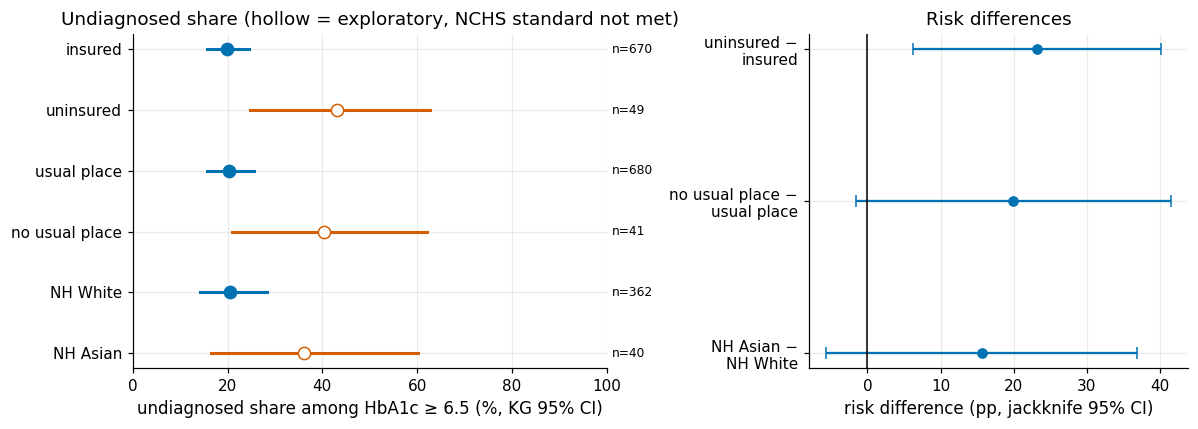

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1.25, 1]})
order = ["insured", "uninsured", "usual place", "no usual place", "NH White", "NH Asian"]
pp = P.loc[order]
yy = np.arange(len(order))[::-1]
for yi, (g, r) in zip(yy, pp.iterrows()):
    expl = r["nchs"].startswith("exploratory")
    col = plots.PALETTE[5] if expl else plots.PALETTE[4]
    ax1.plot([r["kg_low"] * 100, r["kg_high"] * 100], [yi, yi], color=col, lw=2)
    ax1.plot(r["est"] * 100, yi, "o", color=col, mfc="white" if expl else col, ms=8)
    ax1.text(101, yi, f"n={int(r['n'])}", va="center", fontsize=8)
ax1.set_yticks(yy, order)
ax1.set(xlim=(0, 100), xlabel="undiagnosed share among HbA1c ≥ 6.5 (%, KG 95% CI)",
        title="Undiagnosed share (hollow = exploratory, NCHS standard not met)")
yr = np.arange(len(rds))[::-1]
ax2.errorbar(rds["rd_pp"], yr, xerr=[rds["rd_pp"] - rds["ci_low_pp"], rds["ci_high_pp"] - rds["rd_pp"]],
             fmt="o", color=plots.PALETTE[4], capsize=4)
ax2.axvline(0, color="k", lw=1)
ax2.set_yticks(yr, [c.replace(" - ", " −\n") for c in rds["contrast"]])
ax2.set(xlabel="risk difference (pp, jackknife 95% CI)", title="Risk differences")
fig.tight_layout()
plots.savefig(fig, "S5_undiagnosed_inequality",
              caption="Share of HbA1c-positive adults who do not report diabetes (WTPH2YR, Korn-Graubard CI) and risk "
                      "differences with delete-one-PSU jackknife CI. Hollow markers: CI width >= 0.30, exploratory.")
plt.show()

props.to_csv(OUT / "undiagnosed_by_group.csv", index=False)
rds.to_csv(OUT / "undiagnosed_risk_differences.csv", index=False)
logit_tab.to_csv(OUT / "undiagnosed_logit.csv", index=False)
RES["undiagnosed_inequality"] = {
    "proportions": props.set_index("group").drop(columns=["contrast"]).to_dict("index"),
    "risk_differences_pp": rds.set_index("contrast").to_dict("index"),
    "logit": {"n": len(lg), "events": int(lg["undx"].sum()), "formula": FORM,
              "or": logit_tab.set_index("term").to_dict("index")},
}
register("DR-S5-05", "label_bias",
         "Undiagnosed share is higher without insurance or a usual place of care; small cells do not meet NCHS standards",
         "results/S5/undiagnosed_by_group.csv; results/S5/undiagnosed_risk_differences.csv; figures/S5_undiagnosed_inequality.png",
         f"RD uninsured-insured {RD.loc['uninsured - insured', 'rd_pp']:.1f}pp ({RD.loc['uninsured - insured', 'ci_low_pp']:.1f}, "
         f"{RD.loc['uninsured - insured', 'ci_high_pp']:.1f}); uninsured share 43.0% KG width {P.loc['uninsured', 'ci_width']:.2f}; "
         f"adjusted OR no usual place {LT.loc['no usual place', 'OR']:.2f}",
         "Headline = risk difference with JK CI; proportions with KG CI and NCHS flag; insurance and access are audit/stratification variables only; S8 audits L_self vs L_comb by low_access",
         "Report small-cell proportions as headline; drop small groups; put insurance into the model")

**So what.** Among HbA1c-positive adults, 43.0 % of the uninsured but 19.9 % of the insured do not know their
diagnosis: a risk difference of +23.2 pp (6.2, 40.1) whose interval excludes zero. Without a usual place of care
the difference is +19.9 pp (−1.6, 41.5) and for NH Asian versus NH White adults +15.6 pp (−5.7, 36.9); both
intervals include zero. All three group proportions have KG intervals wider than 0.30 (Asian: n = 40,
df = 8), so they are *exploratory and do not meet the NCHS standard*; they are not headlines. Adjusted for age,
sex, BMI and each other (complete cases, n = 704), lacking a usual place of care remains associated with being
undiagnosed (OR 2.6, CI excludes 1), the insurance and Asian ORs are imprecise (CIs include 1), and the design-based weighted fit
gives wider intervals. Consequence for the label: `L_self` systematically under-counts disease in groups with
poorer access, which is why the target is the union `L_comb` and why S8 compares training labels.

## 5 BMI as a biased measurement of adiposity in Asian adults

**Why.** BMI is the main adiposity feature of any non-laboratory screening model. Asian adults develop
diabetes at lower BMI (Araneta et al. 2015; WHO Expert Consultation 2004), so the same BMI value may carry
different information by race: a *feature-level* measurement bias. We compare NH Asian with NH White adults on
(a) the BMI of diabetics, (b) `L_comb` prevalence by BMI band, (c) the discrimination (single-feature ROC-AUC)
of BMI, waist circumference and waist-to-height ratio (WHtR), with a paired bootstrap of the WHtR − BMI gain,
and (d) the sensitivity of the BMI ≥ 25 and ≥ 23 screening cut-offs. These are unweighted *measurement*
properties of the sample; the White group is the control comparison.

In [8]:
grp = {"NH Asian": 6, "NH White": 3}
bmi_dm = []
for g, code in grp.items():
    dm = d[(d["RIDRETH3"] == code) & (d["L_comb"] == 1) & d["BMXBMI"].notna()]
    k = int((dm["BMXBMI"] < 25).sum())
    w = S.weighted_prop(d, (d["BMXBMI"] < 25).astype(float).where(d["BMXBMI"].notna()), weight=WT,
                        domain=((d["RIDRETH3"] == code) & (d["L_comb"] == 1)).to_numpy())
    bmi_dm.append({"group": g, "bmi_lt25": k, "diabetics_with_bmi": len(dm), "share": k / len(dm),
                   "median_bmi": dm["BMXBMI"].median(), "w_share": w["est"], "kg_low": w["kg_low"], "kg_high": w["kg_high"]})
bmi_dm = pd.DataFrame(bmi_dm).set_index("group")
print("BMI < 25 among L_comb diabetics (denominator excludes missing BMI)")
print(bmi_dm.round(3))
assert (bmi_dm.loc["NH Asian", "bmi_lt25"], bmi_dm.loc["NH Asian", "diabetics_with_bmi"]) == (24, 47)
close(bmi_dm.loc["NH Asian", "share"], 0.511, 0.001, "Asian BMI<25"); close(bmi_dm.loc["NH White", "share"], 0.072, 0.001, "White BMI<25")

BANDS = [0, 23, 25, 30, 200]
BLAB = ["<23", "23–24.9", "25–29.9", "≥30"]
d["bmi_band"] = pd.cut(d["BMXBMI"], BANDS, right=False, labels=BLAB)
band_rows = []
for g, code in grp.items():
    for b in BLAB:
        m = ((d["RIDRETH3"] == code) & (d["bmi_band"] == b)).to_numpy()
        w = S.weighted_prop(d, "L_comb", weight=WT, domain=m)
        band_rows.append({"group": g, "bmi_band": b, "n": int(m.sum()), "cases": int(d.loc[m, "L_comb"].sum()),
                          "prev": d.loc[m, "L_comb"].mean(), "w_prev": w["est"], "kg_low": w["kg_low"],
                          "kg_high": w["kg_high"], "df": w["df"], "flags": ";".join(w["nchs_flags"])})
bands = pd.DataFrame(band_rows)
print("\nL_comb prevalence by BMI band (unweighted and WTPH2YR with KG CI)")
print(bands.round(3).to_string(index=False))
B_ = bands.set_index(["group", "bmi_band"])
close(B_.loc[("NH Asian", "<23"), "prev"], 0.121, 0.001, "Asian <23"); close(B_.loc[("NH White", "<23"), "prev"], 0.043, 0.001, "White <23")
close(B_.loc[("NH Asian", "23–24.9"), "prev"], 0.175, 0.001, "Asian 23-25"); close(B_.loc[("NH White", "23–24.9"), "prev"], 0.033, 0.001, "White 23-25")
close(B_.loc[("NH Asian", "<23"), "w_prev"], 0.078, 0.001, "Asian <23 weighted"); close(B_.loc[("NH Asian", "23–24.9"), "w_prev"], 0.140, 0.001, "Asian 23-25 weighted")

BMI < 25 among L_comb diabetics (denominator excludes missing BMI)
          bmi_lt25  diabetics_with_bmi  share  median_bmi  w_share  kg_low  kg_high
group                                                                              
NH Asian        24                  47  0.511        24.9    0.501   0.286    0.715
NH White        35                 488  0.072        32.7    0.067   0.045    0.096

L_comb prevalence by BMI band (unweighted and WTPH2YR with KG CI)
   group bmi_band    n  cases  prev  w_prev  kg_low  kg_high  df          flags
NH Asian      <23  107     13 0.121   0.078   0.030    0.161  14               
NH Asian  23–24.9   63     11 0.175   0.140   0.060    0.262  13               
NH Asian  25–29.9   96     11 0.115   0.053   0.016    0.125  15               
NH Asian      ≥30   44     12 0.273   0.284   0.124    0.499  10 ci_width>=0.30
NH White      <23  485     21 0.043   0.033   0.018    0.055  15               
NH White  23–24.9  423     14 0.033   0.028   0.01

In [9]:
FEATS = {"BMI": "BMXBMI", "waist": "BMXWAIST", "WHtR": "whtr"}
B = C.N_BOOT
rng = np.random.default_rng(E.derive_seed(C.SEED_MASTER, "S5", "auc_bootstrap"))


def auc_set(g):
    out = {}
    for f, col in FEATS.items():
        ok = g[col].notna()
        out[f] = roc_auc_score(g.loc[ok, "L_comb"], g.loc[ok, col])
    both = g["BMXBMI"].notna() & g["whtr"].notna()
    out["gain"] = (roc_auc_score(g.loc[both, "L_comb"], g.loc[both, "whtr"])
                   - roc_auc_score(g.loc[both, "L_comb"], g.loc[both, "BMXBMI"]))
    return out


roc_rows, boot_store = [], {}
for g, code in grp.items():
    sub = d.loc[d["RIDRETH3"] == code, ["L_comb", *FEATS.values()]].reset_index(drop=True)
    est = auc_set(sub)
    pos, neg = np.flatnonzero(sub["L_comb"] == 1), np.flatnonzero(sub["L_comb"] == 0)
    reps = pd.DataFrame([auc_set(sub.iloc[np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))])])
                         for _ in range(B)])
    boot_store[g] = reps
    for k in [*FEATS, "gain"]:
        roc_rows.append({"group": g, "measure": k if k != "gain" else "WHtR − BMI (paired)",
                         "n": int(sub[FEATS[k]].notna().sum()) if k in FEATS else int((sub["BMXBMI"].notna() & sub["whtr"].notna()).sum()),
                         "auc": est[k], "ci_low": reps[k].quantile(0.025), "ci_high": reps[k].quantile(0.975)})
roc = pd.DataFrame(roc_rows)
gain_diff = boot_store["NH Asian"]["gain"] - boot_store["NH White"]["gain"]
print(f"Single-feature ROC-AUC for L_comb (stratified bootstrap, B = {B})")
print(roc.round(3).to_string(index=False))
print(f"Asian minus White WHtR gain: {roc.iloc[3]['auc'] - roc.iloc[7]['auc']:+.3f} "
      f"(bootstrap 95% CI {gain_diff.quantile(.025):+.3f}, {gain_diff.quantile(.975):+.3f})")
RO = roc.set_index(["group", "measure"])
assert gain_diff.quantile(.025) > 0, "Asian WHtR gain no longer exceeds the White gain"
close(RO.loc[("NH Asian", "BMI"), "auc"], 0.573, 0.001, "Asian BMI AUC")
close(RO.loc[("NH Asian", "waist"), "auc"], 0.697, 0.001, "Asian waist AUC")
close(RO.loc[("NH Asian", "WHtR"), "auc"], 0.714, 0.001, "Asian WHtR AUC")
close(RO.loc[("NH White", "BMI"), "auc"], 0.701, 0.001, "White BMI AUC")
close(RO.loc[("NH White", "WHtR"), "auc"], 0.749, 0.001, "White WHtR AUC")
close(RO.loc[("NH Asian", "WHtR − BMI (paired)"), "auc"], 0.136, 0.002, "Asian gain")
close(RO.loc[("NH White", "WHtR − BMI (paired)"), "auc"], 0.048, 0.002, "White gain")
tol_ci = 0.01 if C.IS_FINAL else 0.03   # bootstrap CI bounds: tighter check in FINAL (B=1000)
close(RO.loc[("NH Asian", "WHtR − BMI (paired)"), "ci_low"], 0.092, tol_ci, "Asian gain CI low")
close(RO.loc[("NH Asian", "WHtR − BMI (paired)"), "ci_high"], 0.183, tol_ci, "Asian gain CI high")
close(RO.loc[("NH White", "WHtR − BMI (paired)"), "ci_low"], 0.039, tol_ci, "White gain CI low")
close(RO.loc[("NH White", "WHtR − BMI (paired)"), "ci_high"], 0.059, tol_ci, "White gain CI high")

Single-feature ROC-AUC for L_comb (stratified bootstrap, B = 100)
   group             measure    n   auc  ci_low  ci_high
NH Asian                 BMI  310 0.573   0.489    0.655
NH Asian               waist  296 0.697   0.614    0.762
NH Asian                WHtR  296 0.714   0.646    0.776
NH Asian WHtR − BMI (paired)  296 0.137   0.097    0.184
NH White                 BMI 3370 0.701   0.676    0.723
NH White               waist 3274 0.751   0.729    0.775
NH White                WHtR 3268 0.749   0.728    0.772
NH White WHtR − BMI (paired) 3264 0.049   0.038    0.058
Asian minus White WHtR gain: +0.088 (bootstrap 95% CI +0.045, +0.138)


In [10]:
cut_rows = []
for g, code in grp.items():
    sub = d[(d["RIDRETH3"] == code) & d["BMXBMI"].notna()]
    y = sub["L_comb"].eq(1)
    for cut in (25, 23):
        flag = sub["BMXBMI"] >= cut
        cut_rows.append({"group": g, "rule": f"BMI ≥ {cut}", "sensitivity": flag[y].mean(),
                         "specificity": (~flag[~y]).mean(), "flagged_share": flag.mean(), "cases": int(y.sum())})
cuts = pd.DataFrame(cut_rows)
print(cuts.round(3).to_string(index=False))
CU = cuts.set_index(["group", "rule"])
close(CU.loc[("NH Asian", "BMI ≥ 25"), "sensitivity"], 0.489, 0.001, "Asian sens BMI>=25")
close(CU.loc[("NH White", "BMI ≥ 25"), "sensitivity"], 0.928, 0.001, "White sens BMI>=25")
close(CU.loc[("NH Asian", "BMI ≥ 23"), "sensitivity"], 0.723, 0.001, "Asian sens BMI>=23")
close(CU.loc[("NH Asian", "BMI ≥ 23"), "specificity"], 0.357, 0.001, "Asian spec BMI>=23")

   group     rule  sensitivity  specificity  flagged_share  cases
NH Asian BMI ≥ 25        0.489        0.555          0.452     47
NH Asian BMI ≥ 23        0.723        0.357          0.655     47
NH White BMI ≥ 25        0.928        0.303          0.731    488
NH White BMI ≥ 23        0.957        0.161          0.856    488


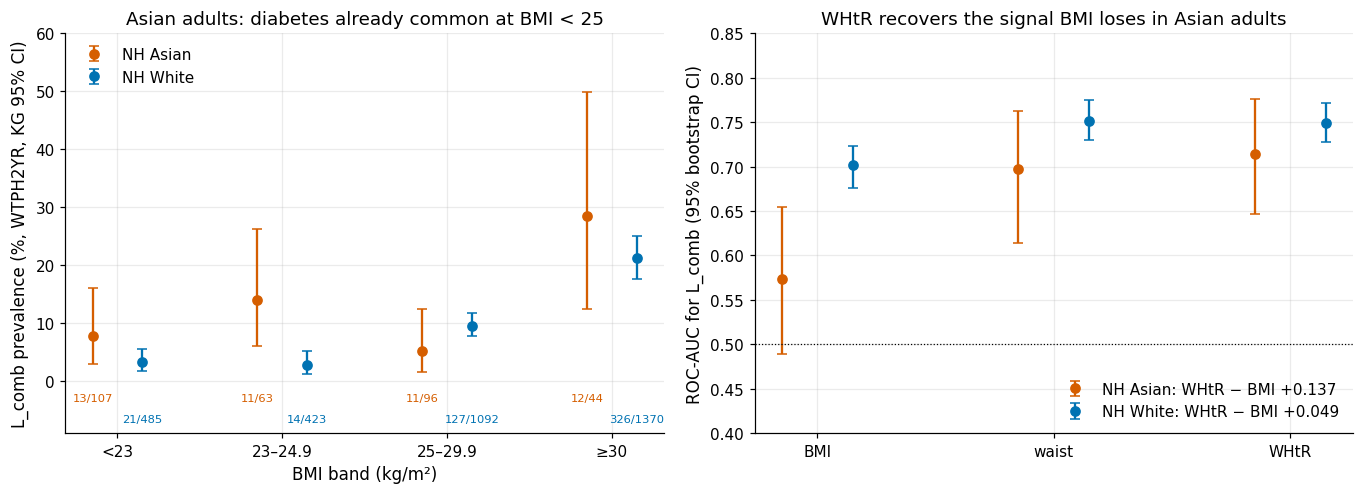

In [11]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.6))
xb = np.arange(len(BLAB))
for i, (g, col) in enumerate([("NH Asian", plots.PALETTE[5]), ("NH White", plots.PALETTE[4])]):
    sb = bands[bands["group"] == g]
    off = (i - 0.5) * 0.3
    ax1.errorbar(xb + off, sb["w_prev"] * 100, yerr=[(sb["w_prev"] - sb["kg_low"]) * 100, (sb["kg_high"] - sb["w_prev"]) * 100],
                 fmt="o", color=col, capsize=3, label=g)
    for x_, (_, r) in zip(xb + off, sb.iterrows()):
        ax1.text(x_, -3.5 - 3.5 * i, f"{r['cases']}/{r['n']}", ha="center", fontsize=7.5, color=col)
ax1.set_xticks(xb, BLAB)
ax1.set(xlabel="BMI band (kg/m²)", ylabel="L_comb prevalence (%, WTPH2YR, KG 95% CI)", ylim=(-9, 60),
        title="Asian adults: diabetes already common at BMI < 25")
ax1.legend(loc="upper left")
meas = ["BMI", "waist", "WHtR"]
for i, (g, col) in enumerate([("NH Asian", plots.PALETTE[5]), ("NH White", plots.PALETTE[4])]):
    rr = RO.loc[g].loc[meas]
    off = (i - 0.5) * 0.3
    ax2.errorbar(np.arange(3) + off, rr["auc"], yerr=[rr["auc"] - rr["ci_low"], rr["ci_high"] - rr["auc"]],
                 fmt="o", color=col, capsize=3,
                 label=f"{g}: WHtR − BMI {RO.loc[(g, 'WHtR − BMI (paired)'), 'auc']:+.3f}")
ax2.axhline(0.5, color="k", lw=0.8, ls=":")
ax2.set_xticks(range(3), meas)
ax2.set(ylabel="ROC-AUC for L_comb (95% bootstrap CI)", ylim=(0.4, 0.85),
        title="WHtR recovers the signal BMI loses in Asian adults")
ax2.legend(loc="lower right")
fig.tight_layout()
plots.savefig(fig, "S5_asian_bmi_whtr",
              caption="Left: L_comb prevalence by BMI band, NH Asian vs NH White (WTPH2YR, Korn-Graubard CI; labels = cases/n). "
                      "Right: single-feature ROC-AUC of BMI, waist and WHtR with stratified bootstrap CI; legend = paired WHtR - BMI gain.")
plt.show()

roc.to_csv(OUT / "bmi_race_roc.csv", index=False)
bands.to_csv(OUT / "bmi_band_prevalence.csv", index=False)
cuts.to_csv(OUT / "bmi_cutoff_sensitivity.csv", index=False)
RES["asian_bmi"] = {
    "bmi_lt25_among_diabetics": bmi_dm.to_dict("index"),
    "band_prevalence": {f"{g}|{b}": v for (g, b), v in B_[["n", "cases", "prev", "w_prev", "kg_low", "kg_high"]].to_dict("index").items()},
    "auc": {f"{g}|{m}": v for (g, m), v in RO[["n", "auc", "ci_low", "ci_high"]].to_dict("index").items()},
    "gain_difference_asian_minus_white": {"est": float(RO.loc[("NH Asian", "WHtR − BMI (paired)"), "auc"] - RO.loc[("NH White", "WHtR − BMI (paired)"), "auc"]),
                                          "ci_low": gain_diff.quantile(.025), "ci_high": gain_diff.quantile(.975)},
    "cutoffs": {f"{g}|{r}": v for (g, r), v in CU.to_dict("index").items()},
    "n_boot": B,
}
register("DR-S5-06", "measurement_bias",
         "BMI under-measures diabetes-relevant adiposity in NH Asian adults; WHtR recovers discrimination",
         "results/S5/bmi_race_roc.csv; results/S5/bmi_band_prevalence.csv; figures/S5_asian_bmi_whtr.png",
         f"BMI<25 among diabetics: Asian 24/47 (51.1%) vs White {pct(bmi_dm.loc['NH White', 'share'])}; AUC gain WHtR-BMI Asian "
         f"{RO.loc[('NH Asian', 'WHtR − BMI (paired)'), 'auc']:+.3f} ({RO.loc[('NH Asian', 'WHtR − BMI (paired)'), 'ci_low']:.3f}, "
         f"{RO.loc[('NH Asian', 'WHtR − BMI (paired)'), 'ci_high']:.3f}) vs White {RO.loc[('NH White', 'WHtR − BMI (paired)'), 'auc']:+.3f}",
         "Pre-register P14 (WHtR replaces waist, BMI kept) as S8 mitigation arm with White control; Asian results exploratory (40 A1c-positive cases); no group-specific thresholds",
         "Race-specific BMI cut-offs in the model; adding WHtR on top of waist (redundant); race x BMI interaction (undetectable, S4)",
         hyp_id="H-P14")

**So what.** Half of the Asian diabetics (24/47, 51.1 %) have a "normal" BMI below 25, against 7.2 % of White
diabetics. Asian adults with BMI < 23 already have an `L_comb` prevalence of 12.1 % (White 4.3 %), and in the
23–24.9 band 17.5 % (White 3.3 %; unweighted). Weighted, as in the figure, the contrasts are 7.8 % vs 3.3 % and
14.0 % vs 2.8 %, with wide Asian intervals (63–107 adults per band). Consequently BMI barely discriminates in Asian adults
(AUC 0.573), while waist (0.697) and WHtR (0.714) do. The paired WHtR − BMI gain is +0.137 in Asian adults
(bootstrap CI roughly 0.09–0.18) against +0.049 in White adults (CI roughly 0.04–0.06); the Asian-minus-White
difference in gain, +0.088, has a bootstrap CI that excludes zero. (Exact bounds are printed above; they move
slightly between FAST, B = 100, and FINAL, B = 1,000.) A BMI ≥ 25 rule finds only 48.9 % of Asian cases
(White 92.8 %); lowering the cut-off to 23 (the ADA recommendation for Asian Americans) raises sensitivity to
72.3 % at a specificity of only 35.7 %. The direction agrees with Araneta et al. (2015). With 40–50 Asian cases
this is a measurement *signal*, not a definitive estimate: it motivates the pre-registered WHtR arm (P14) in S8,
where WHtR replaces waist rather than being added.

In [12]:
reg_df = pd.DataFrame(REG).sort_values("dr_id").reset_index(drop=True)
reg_path = C.GOVERNANCE_DIR / "register" / "S5.csv"
reg_path.parent.mkdir(parents=True, exist_ok=True)
reg_df.to_csv(reg_path, index=False, lineterminator="\n")
R.save_section("S5", RES)
print(f"{len(reg_df)} register rows -> {reg_path.relative_to(C.ROOT).as_posix()}; results -> results/metrics_S5.json")
print(reg_df[["dr_id", "type", "decision"]].to_string(index=False))

5 register rows -> governance/register/S5.csv; results -> results/metrics_S5.json
   dr_id             type                                                                                                                                                                            decision
DR-S5-02      label_audit                                                            Use the union L_comb as training target; report PA/NA next to kappa; keep L_self and L_A1c as sensitivity labels SL2/SL1
DR-S5-03       label_bias                                                    Reject L_A1c as the sole target; keep stratum D_controlled as a 3x3 evaluation column; medication is audit-only (post-diagnosis)
DR-S5-04  label_semantics             Frame E-SCREEN positives as 'not diagnosed despite contact'; DIQ160/DIQ180 excluded as features (post-test information); borderline kept negative in L_comb and flagged
DR-S5-05       label_bias Headline = risk difference with JK CI; proportions with KG CI and NC